# Parking Lot Simulation Analysis

This notebook displays surface pressure from every pressure output in a selected parking lot simulation as an interactive animation. Each run is expected in its own folder under `LW_Runs`, with the folder name and output-file prefix matching the run name.

Choose a run by changing `run_name` in the setup cell below.

## 1. Import packages

In [5]:
import os
from glob import glob

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML, display
from matplotlib.animation import FuncAnimation
from matplotlib.colors import LogNorm
from parflow import Run
from parflow.tools.io import read_pfb

## 2. Select a run and load its pressure outputs

In [6]:
# Select any completed run in the LW_Runs folder.
run_name = "LW_ParkingLot3"
run_dir = os.path.join(os.getcwd(), "LW_Runs", run_name)
run_definition = os.path.join(run_dir, f"{run_name}.pfidb")

if not os.path.isfile(run_definition):
    raise FileNotFoundError(f"Run definition not found: {run_definition}")

pressure_files = sorted(
    glob(os.path.join(run_dir, f"{run_name}.out.press.*.pfb")),
    key=lambda path: int(os.path.basename(path).split(".")[-2]),
)
if not pressure_files:
    raise FileNotFoundError(f"No pressure output files found in {run_dir}")

run = Run.from_definition(run_definition)
data = run.data_accessor
dx = data.dx
dy = data.dy
print(f"Run: {run_name}")
print(f"Pressure output frames: {len(pressure_files)}")
print(f"Grid spacing: dx={dx}, dy={dy}")

Run: LW_ParkingLot3
Pressure output frames: 21
Grid spacing: dx=1000.0, dy=1000.0


## 3. Extract surface pressure for every timestep

ParFlow pressure arrays are ordered by vertical layer, then y and x. As in the tilted-V analysis notebook, the surface layer is selected with `[-1, :, :]`.

Positive surface pressure uses Matplotlib's built-in reversed Turbo color map (red for low positive pressure, blue for high pressure) on a logarithmic scale from 0.000001 to 10 m; values above 10 m are capped. Zero and negative pressures are shown in brown.

In [7]:
surface_pressure = np.stack(
    [read_pfb(path)[-1, :, :] for path in pressure_files],
    axis=0,
)

# Exclude inactive cells from each frame.
surface_mask = data.mask[-1, :, :] > 0
surface_pressure = np.where(surface_mask[None, :, :], surface_pressure, np.nan)

vmin = np.nanmin(surface_pressure)
vmax = np.nanmax(surface_pressure)
print(f"Surface pressure range: {vmin:.3f} to {vmax:.3f} m")

Surface pressure range: -1190.945 to 2.862 m


## 4. Animate surface pressure

In [8]:
pressure_color_floor = 1e-6
surface_pressure_for_plot = np.clip(surface_pressure, pressure_color_floor, 10.0)
surface_pressure_for_plot = np.where(
    surface_pressure <= 0, pressure_color_floor / 10, surface_pressure_for_plot
)
pressure_norm = LogNorm(vmin=pressure_color_floor, vmax=10.0, clip=False)
pressure_colormap = plt.get_cmap("turbo_r").with_extremes(under="saddlebrown")

ny, nx = surface_pressure.shape[1:]
extent = (0, nx * dx, 0, ny * dy)
fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(
    surface_pressure_for_plot[0],
    origin="lower",
    extent=extent,
    aspect="auto",
    cmap=pressure_colormap,
    norm=pressure_norm,
)
colorbar = fig.colorbar(image, ax=ax, extend="min")
colorbar.set_label("Surface pressure head [m], log scale (brown = 0 or less)")
colorbar.set_ticks([pressure_color_floor, 1e-4, 1e-2, 1.0, 10.0])
colorbar.set_ticklabels(["0.000001", "0.0001", "0.01", "1", "10"])
ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")

def update(frame):
    image.set_data(surface_pressure_for_plot[frame])
    timestep = os.path.basename(pressure_files[frame]).split(".")[-2]
    ax.set_title(f"{run_name} - surface pressure, timestep {timestep}")
    return (image,)

animation = FuncAnimation(
    fig, update, frames=len(pressure_files), interval=300, blit=False, repeat=True
)
plt.close(fig)
display(HTML(animation.to_jshtml()))

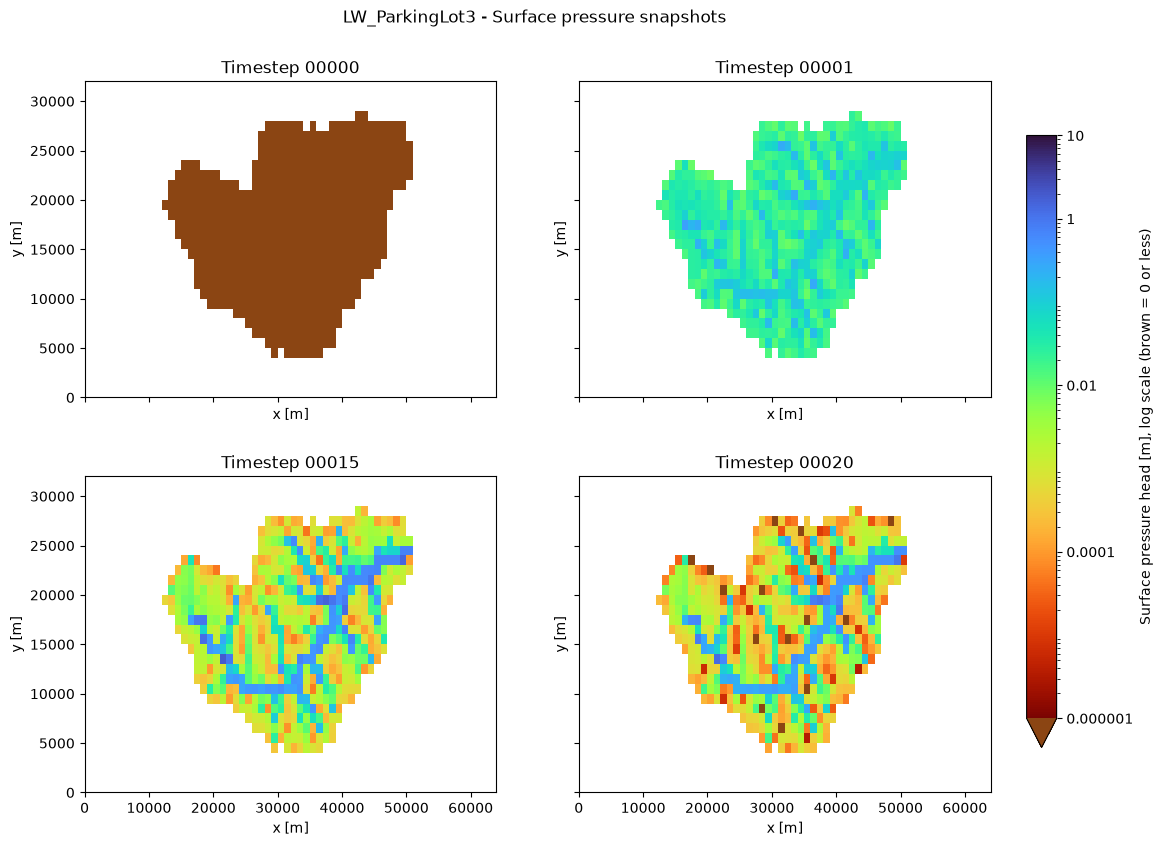

In [12]:
# Set what for time frames you want to look at here 
# or use the lines below to evenely space them over the run
selected_frame_indices = [0,1,15,20]


# This does four frames evenly spaced over the run time 
#selected_frame_indices = np.rint(
#    np.linspace(0, len(pressure_files) - 1, num=4)
#).astype(int).tolist()

if len(selected_frame_indices) != 4 or len(set(selected_frame_indices)) != 4:
    raise ValueError("The run must contain at least four distinct pressure timesteps.")
if any(index < 0 or index >= len(pressure_files) for index in selected_frame_indices):
    raise IndexError("Every selected frame index must be within the available outputs.")

fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharex=True, sharey=True)
for ax, frame in zip(axes.flat, selected_frame_indices):
    image = ax.imshow(
        surface_pressure_for_plot[frame],
        origin="lower",
        extent=extent,
        aspect="auto",
        cmap=pressure_colormap,
        norm=pressure_norm,
    )
    timestep = os.path.basename(pressure_files[frame]).split(".")[-2]
    ax.set_title(f"Timestep {timestep}")
    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")

fig.suptitle(f"{run_name} - Surface pressure snapshots")
fig.subplots_adjust(right=0.88, top=0.90, wspace=0.2, hspace=0.25)
colorbar_ax = fig.add_axes([0.91, 0.16, 0.025, 0.68])
colorbar = fig.colorbar(image, cax=colorbar_ax, extend="min")
colorbar.set_label("Surface pressure head [m], log scale (brown = 0 or less)")
colorbar.set_ticks([pressure_color_floor, 1e-4, 1e-2, 1.0, 10.0])
colorbar.set_ticklabels(["0.000001", "0.0001", "0.01", "1", "10"])
plt.show()
